# Face Recognition with PCA on the olivetti dataset

Project question: how well can PCA (eigenfaces) + a simple classifier identify which of 40 people are in a face photo, and how many PCA components are enough?

**Motivation:**
A photo has 4096 pixels, but most of them are redundant. What PCA does is that it squeezes them into a few dozen numbers, and if identification still works, we learn how little information a face needs, and we get a model that is fast and less noisy.

Basically, this is multiclass classification task with input of a 64x64 grayscale photo (4096 pixel values) and output of the subject id (0 to 39). 

## 1 Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from src.common import seed, cv, load_data, evaluate

np.random.seed(seed)
sns.set_theme(style="whitegrid")

## 2 EDA

Here, we validate our data: size, types, missing values, class balance.

In [2]:
x, y = load_data()

print('x shape:', x.shape, '| y shape:', y.shape)
print('dtype:', x.dtype)
print('pixel range:', x.min(), 'to', x.max())
print('missing values:', np.isnan(x).sum())
print('subjects:', len(np.unique(y)), '| images per subject:', np.unique(np.bincount(y)))

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to C:\Users\mcche\scikit_learn_data
x shape: (400, 4096) | y shape: (400,)
dtype: float32
pixel range: 0.0 to 1.0
missing values: 0
subjects: 40 | images per subject: [10]


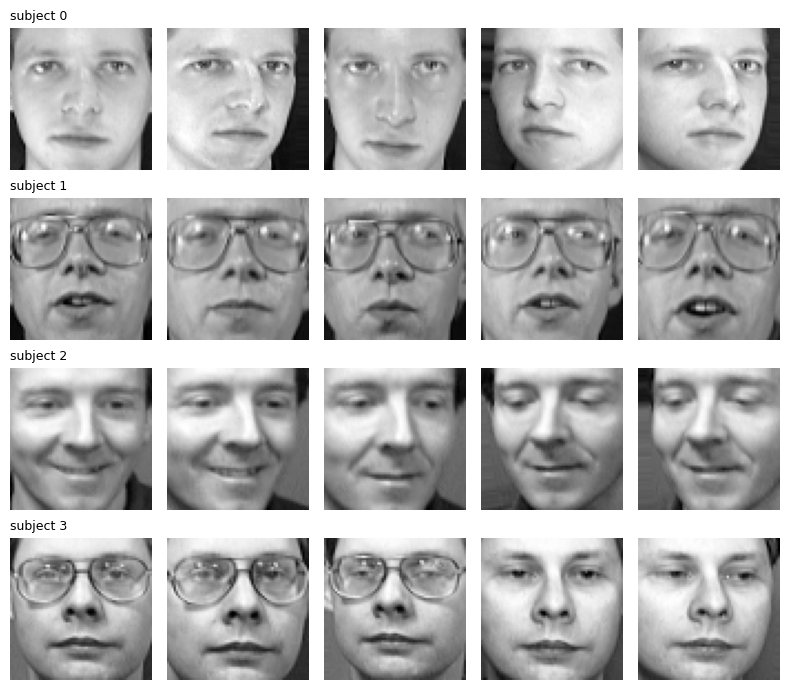

In [3]:
# first 5 photos of 4 different people
fig, axes = plt.subplots(4, 5, figsize=(8, 7))
for row, subject in enumerate([0, 1, 2, 3]):
    for col, img in enumerate(x[y == subject][:5]):
        axes[row, col].imshow(img.reshape(64, 64), cmap='gray')
        axes[row, col].axis('off')
    axes[row, 0].set_title(f'subject {subject}', loc='left', fontsize=9)
plt.tight_layout()
plt.show()

**about our data:** the faces are cropped, centered and front-facing on a dark background. photos of the same person differ in expression, small head turns, and sometimes glasses.

**what we have:**
- 400 images, 64x64 = 4096 features per image, pixel values already scaled to 0-1
- 40 subjects with exactly 10 images each, so the classes are balanced
- no missing values
- main problem: only 10 photos per person. in 5-fold cv a model sees just 8 photos of each person, so results will be noisy.

## 3 Validation Scheme

Since we are doing identification, every person must appear in both the training and the test data, so we use a **stratified k-fold** on the subject id. 

The data is ordered by subject, so we also shuffle, with a fixed seed. 5 folds because with 10 photos per person it gives exactly 8 train and 2 test photos per person.

The `cv` object is defined once in `src/common.py` and used for every model, so all models are scored on identical folds.

In [4]:
train_idx, test_idx = next(cv.split(x, y))
print('train size:', len(train_idx), '| test size:', len(test_idx))
print('test photos per subject in fold 1:', np.unique(np.bincount(y[test_idx])))

train size: 320 | test size: 80
test photos per subject in fold 1: [2]


Right now, each fold has 320 training and 80 test images, with exactly 2 test photos per person, so every image is used as test data exactly once across the 5 folds.

## 4 Metrics

Metrics are computed per fold and reported as mean and std over the 5 folds:
- **accuracy:** the share of photos identified correctly.
- **macro f1:** f1 per person, averaged equally over the 40 people.

Each fold has only 80 test images, so one photo is worth 1.25 points, and a gap between two models smaller than the std is not a real difference, so that's why it's important to report both mean and std.

Both metrics are computed by `evaluate()` in `src/common.py`. it returns one row per model with `name`, `acc_mean`, `acc_std`, `f1_mean`, `f1_std`. Chance level is 1/40 = 2.5% accuracy.

## 5 Baseline

Here, we establish a simple baseline to get our first metrics and to have something to improve upon.
**Baselines:**
- **dummy (most frequent):** always predicts the same person, this is the chance level.
- **knn on raw pixels** (1 neighbour): "find the most similar photo" approach.
- **logistic regression on raw pixels:** a simple linear model.

any PCA model later has to be better than these above

In [11]:
results = []

baselines = {
    'dummy (most frequent)': DummyClassifier(strategy='most_frequent'),
    'knn raw pixels': KNeighborsClassifier(n_neighbors=1),
    'logreg raw pixels': LogisticRegression(max_iter=1000),
}
for name, model in baselines.items():
    results.append(evaluate(name, model, x, y))

pd.DataFrame(results).round(3)

,name,acc_mean,acc_std,f1_mean,f1_std
0,dummy (most frequent),0.025,0.000,0.001,0.000
1,knn raw pixels,0.933,0.013,0.924,0.015
2,logreg raw pixels,0.980,0.006,0.979,0.007


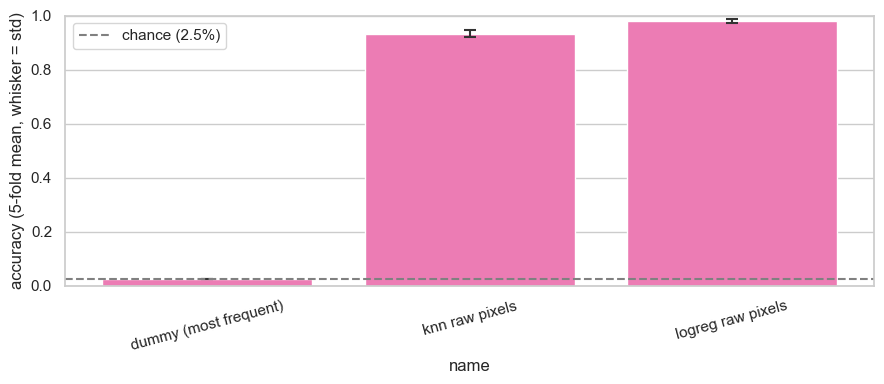

In [ ]:
# ai generated part
plt.figure(figsize=(9, 4))
df = pd.DataFrame(results)
ax = sns.barplot(data=df,x="name",y="acc_mean",color="#FF69B4", capsize=0.1,err_kws={"linewidth": 1.5, "color": "#333333"})

ax.errorbar(x=range(len(df)),y=df["acc_mean"],yerr=df["acc_std"],fmt="none",ecolor="#333333",capsize=4,capthick=1.5)

plt.axhline(1 / 40, color="gray", linestyle="--", label="chance (2.5%)")
plt.ylabel("accuracy (5-fold mean, whisker = std)")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(); plt.tight_layout(); plt.show()

On the chart above, each bar is the mean accuracy over the 5 folds, the whisker is the std across folds, and the dashed line is chance (2.5%). 


The dummy reaches 2.5% accuracy and about 0.001 macro f1, which is exactly what we would expect. KNN on raw pixels reaches F1-score of 0.924 and accuracy of 0.933 and logistic regression F1-score of 0.979 and accuracy of 0.980. The baseline to beat is the logistic regression model.

std is insignificant for now

## 6 PCA

Here, we apply PCA on our data. PCA is inside a `Pipeline` with a cross-validation, which refits PCA on the training folds only. This way we avoid data leakage.

**Modeling choices:**
- **No scaler:** the pixels are already on one 0-1 scale, and pca subtracts the mean by itself. Standardising would give every pixel equal weight, including pixels that barely vary and mostly carry noise. 
- **50 components** is a starting point, not a tuned value. 
- **1-nn classifier**, so the pipeline is directly comparable to the raw-pixel knn baseline: the only difference is PCA.

In [7]:
pca_knn = Pipeline([
    ('pca', PCA(n_components=50, random_state=seed)),
    ('clf', KNeighborsClassifier(n_neighbors=1)),
])
pca_knn_scaled = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=50, random_state=seed)),
    ('clf', KNeighborsClassifier(n_neighbors=1)),
])

results.append(evaluate('pca50 + knn', pca_knn, x, y))
results.append(evaluate('scaler + pca50 + knn', pca_knn_scaled, x, y))

pd.DataFrame(results).round(3)

,name,acc_mean,acc_std,f1_mean,f1_std
0,dummy (most frequent),0.025,0.000,0.001,0.000
1,knn raw pixels,0.933,0.013,0.924,0.015
2,logreg raw pixels,0.980,0.006,0.979,0.007
3,pca50 + knn,0.930,0.013,0.924,0.016
4,scaler + pca50 + knn,0.930,0.010,0.924,0.009


**outcome:** pca(50) + knn reaches 0.930 accuracy, versus 0.933 for knn on raw pixels. with a scaler it reaches 0.933, so we keep the scaler in, since we can get to the same result and save space/time. 

In [13]:
results.append(evaluate('my model', pca_knn_scaled, x, y))
pd.DataFrame(results).round(3)

,name,acc_mean,acc_std,f1_mean,f1_std
0,dummy (most frequent),0.025,0.000,0.001,0.000
1,knn raw pixels,0.933,0.013,0.924,0.015
2,logreg raw pixels,0.980,0.006,0.979,0.007
3,my model,0.930,0.010,0.924,0.009
